# E66: Can the 67M's fine-tunes get a causal label that owes nothing to VPD?

## The answer

Not yet. The probe could not give any fine-tune a label: neither hand-built control was usable, and switching off neurons cannot tell old from new on this model. Reading the context patch on the saved fine-tunes anyway moved no label. On E62's pair the patch runs the way E62's head test does, but on the other key maps it runs against the assumption that copying is reuse. No row moves, and nothing here was filed as a test.


## What we were trying to test

`GOALS.md` asks whether post-training teaches new capabilities or strengthens existing ones. On the 67M every row of the method table takes that answer from how the task was built: a copy map is assumed to be reuse, a random map is assumed to be new. E66 looks for a label that comes from neither VPD nor the task's construction, so the table's rows could be scored against something causal.

**The patch.** Take two contexts with the same key and the same target, one where W0 favours the target and one where it does not. Write W0's block input from the first context into the second, at the answer position only, and measure how much the target's log-odds rise. That rise is the response $R$. The **patch ratio** is $T = \bar R(\text{fine-tuned state}) / \bar R(W_0)$. W0 reads 1 by definition. A state that passes W0's difference through unchanged reads about 1, one that strengthens it reads above 1, and one that damps it reads below 1. The model has four blocks, so the patch can sit at the input of block 1, 2 or 3, and block 3 is the last.

**The off-map ratio.** $T_{off}$ is the same reading for a token the map does not train, with the map's own target taken out of the odds. $Q = T / T_{off}$ removes what any sharpening of the model would do to both. W0 reads 1 on both.

**The neuron reading.** $U$ is the share of a state's gain lost when W0's top neurons are mean-ablated in both models, against the same for matched random neurons.

**Three hand-built controls, each ruling out one reading of a number.**

- **The write** is a table from keys to answers written by hand into block 3's MLP output. It is new by construction, so it should read about 1 on $T$ and sit on the random neurons on $U$.
- **Amplify** multiplies the output of W0's most helpful neurons. It is reuse by algebra, so it should read above the write. It is the only control that could show $T$ can read high at all.
- **Sharpening** is a 30-step fine-tune to W0's own distribution at temperature 0.5. $T$ should rise above 1 and $Q$ should stay near 1.

**The states.** Fourteen saved fine-tunes, no new training. Six are E62's: a map that copies an earlier token at a new marker, and a lookup on the same marker, three seeds each. Eight are E46's: two copy maps whose value is the key itself and two random maps, on two key sets, two seeds each. Six more are E62's states rescaled to the other map's size.

**Held fixed:** the model, the key, the target, and W0 as the donor. **Varied:** the context and the block.


## What we expected, and why

The job was a feasibility probe with filed rules for the controls only, and no state had an expected value. The first job stopped at its filed control. The user then chose to read the patch on the saved states as exploratory, with the neuron reading off.

Fable's advice before that second job set out two outcomes. If the copy maps read near 1 at block 1, like the write, the patch has shown no fine-tune it can see. If they read above the write and the random maps do not, rules would be worth filing. Behind both sits the plain expectation that a copy map, assumed to be reuse, reads at least as high as a random map, assumed to be new.


In [1]:
from pathlib import Path
from IPython.display import Image, display
FIG = Path("../experiments/interchange_67m/figures")
def show(name):
    display(Image(filename=str(FIG / name), width=760))


## What we observed

### Could the probe's controls be used?


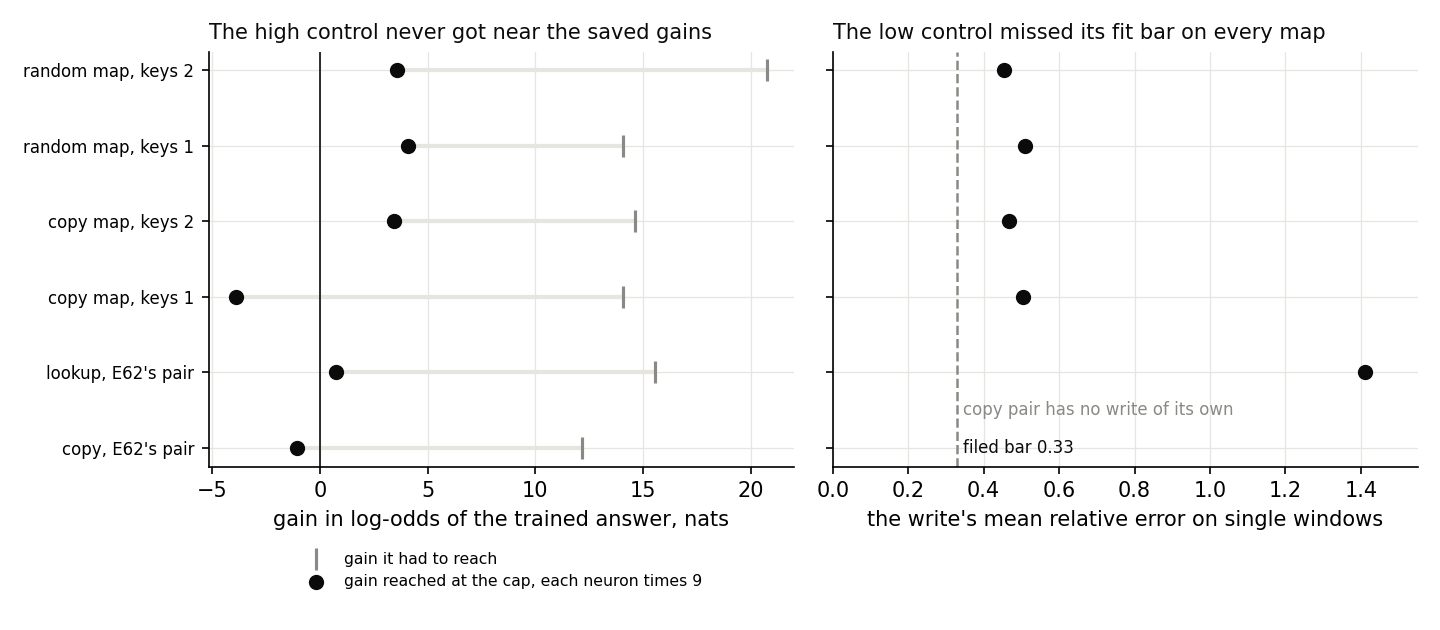

In [2]:
show("controls.png")


**Reading it.** No, and the job stopped there, as filed. Multiplying up to 4,096 neurons by nine reached at most 4.1 nats, where the saved fine-tunes gain 12 to 21. Switching off all of W0's neurons moves its half-known map by only 2.8 nats, so W0's own neurons cannot supply such a gain. Amplify therefore gave no usable reading, and nothing of known kind has ever read high on $T$.

The write missed its fit bar of 0.33 on every map, at 0.45 to 1.41, so it is a reference here and not a passed control. Its $T$ was as hoped on three maps, 0.99 to 1.09 at block 1. On the lookup's pool it fit worst and read 2.5 at block 3, so E62's pair has no trustworthy low reference.

Sharpening was the one control that behaved. It cleared 1 by three noise units on three of six maps, and its $Q$ stayed within 0.13 of 1 on all six.


### Can switching off neurons separate old from new?


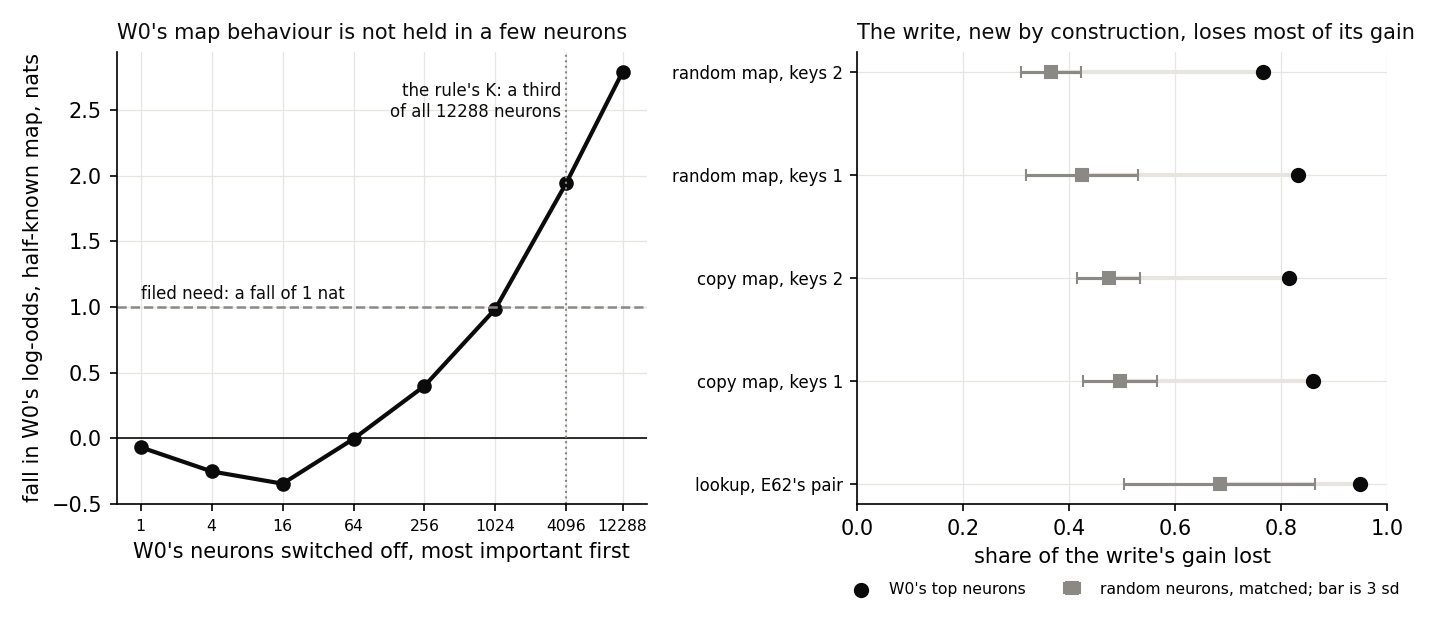

In [3]:
show("units.png")


**Reading it.** No, this reading is dead on this model. The filed rule asks for the fewest neurons whose removal lowers W0's log-odds by 1 nat. That came to 4,096, a third of the network, and 1,024 missed by only 0.014. At 64 neurons or fewer, removal raises W0's log-odds, because the ranking keeps neurons pushing against the target. The write is new by construction, yet it loses 0.77 to 0.95 of its gain. Matched random neurons cost it 0.37 to 0.68. The write reads old activations by being a linear readout of them, so any new update built that way loses its gain too, and the negative control fails by design. No state was read on this measure.


### On E62's pair, does the patch run the way E62's head test does?


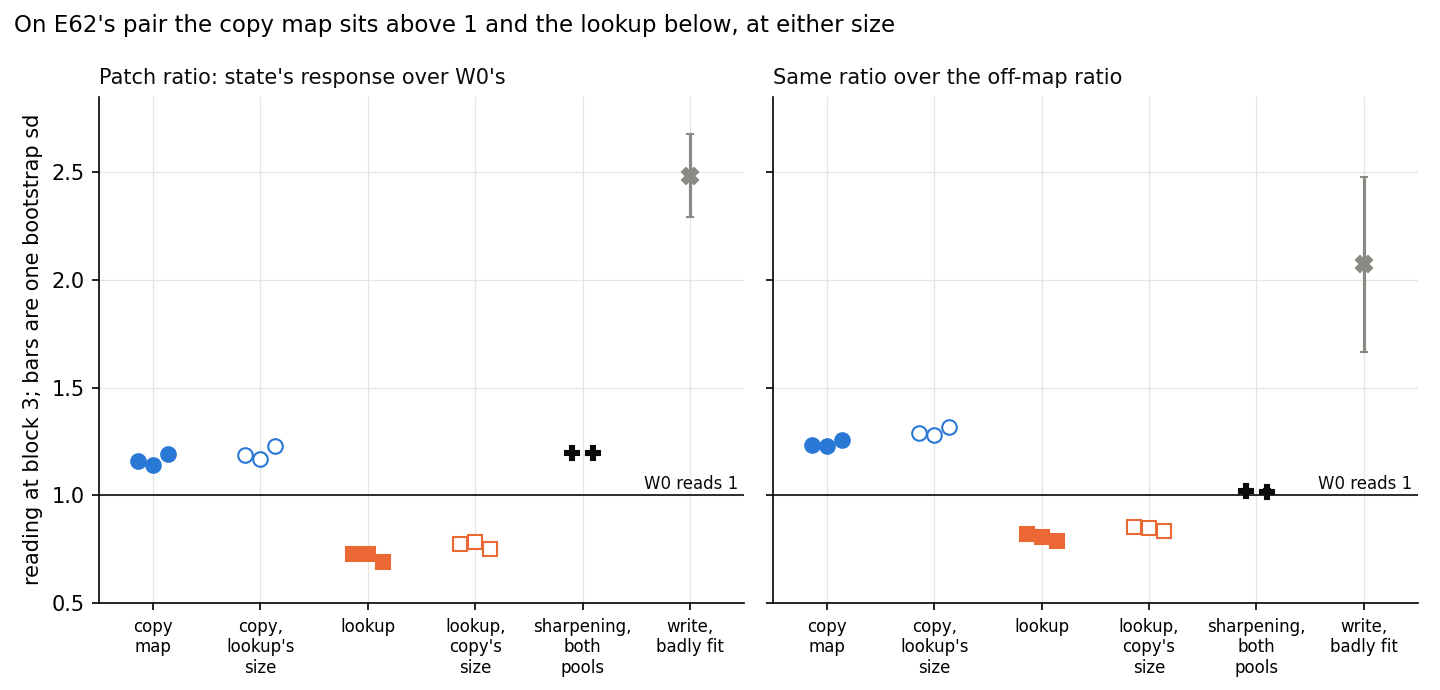

In [4]:
show("cue_pair.png")


**Reading it.** Yes in direction, at the one block where W0 responds. E62 found that switching off head (2,4) takes about half of the copying map's gain and none of the lookup's. At block 3 the copying map reads $T$ of 1.14 to 1.19, and the lookup reads 0.69 to 0.73. Rescaling each state to the other's size moves it by 0.06 or less, against a gap of about 0.45, so size does not make this gap.

Sharpening reads about 1.2 on the same two pools, so $T$ alone cannot tell the copying map from a model that has only sharpened. $Q$ does separate them, at 1.23 to 1.25 against 1.02. Most of that comes from the off-map ratio, which falls to about 0.94 on the copying map and rises to about 1.17 under sharpening.

Three cautions limit this. The two maps use different pairs. The copying map's are a window and that window with its token replaced, and the lookup's are ranked on W0's own log-odds, so only the lookup's carry selection inflation. The patch sits after head (2,4) and overwrites it at the answer position, so it does not read what E62 read. And block 3 is the last block, so the reading sees only what that block and the output do.


### On the key maps, does the assumed reuse read higher than the assumed new?


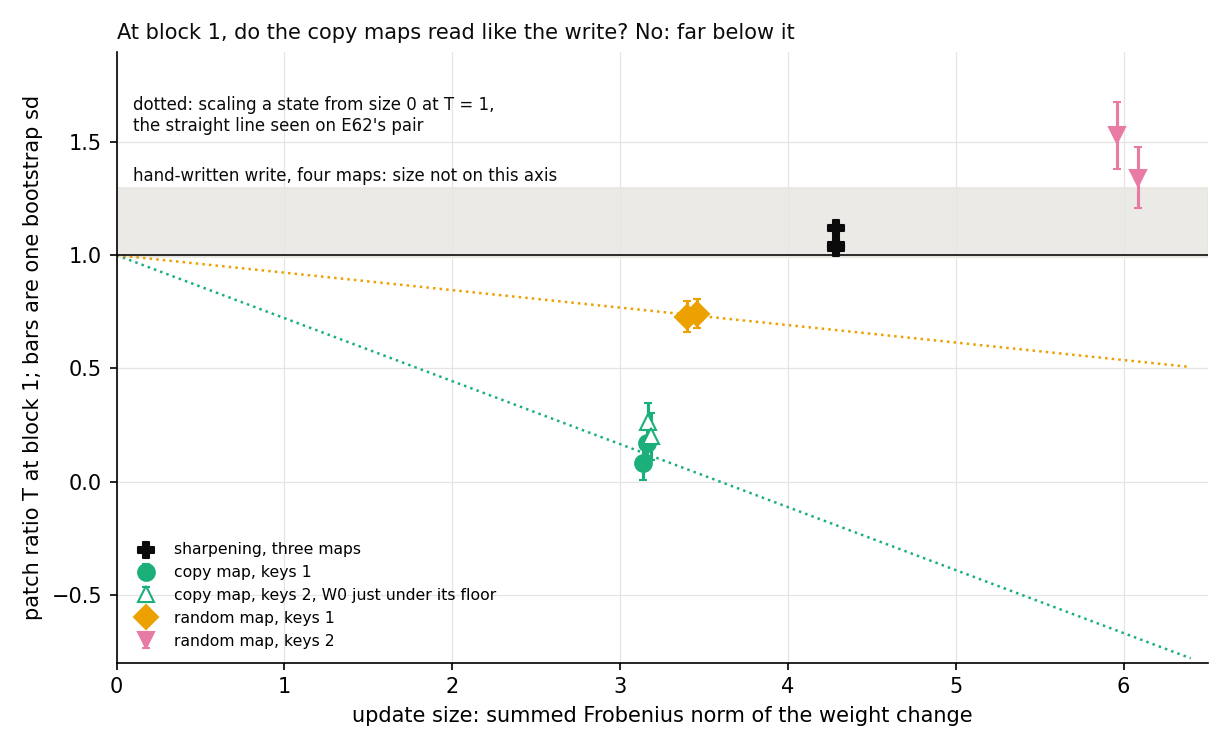

In [5]:
show("key_maps.png")


**Reading it.** No, it runs the other way at the one block where the marks allow a reading. At block 1 W0 responds on all four maps. The steering share there is under 0.12, so the patch is not overwriting the update's gain.

| at block 1 | size | $T$ |
|---|---|---|
| copy maps, four states | 3.1 to 3.2 | 0.08 to 0.26 |
| first random map | 3.40 to 3.46 | 0.73 to 0.74 |
| second random map | 6.0 to 6.1 | 1.34 to 1.53 |
| the write, four maps | not stored | 0.99 to 1.30 |
| sharpening, three maps | 4.3 | 1.03 to 1.12 |

Both of Fable's outcomes are missed. The copy maps sit 8 to 15 noise units below 1, so they do not read near 1 like the write. They sit at least 7 units below the write, so they do not read above it either.

The random maps do not behave as a group. The first sits about three noise units below its write. The second sits above its write on one seed of two. The two differ by 0.70, more than copy and random differ on the first key set, at 0.61. On the second key set copy and random differ by 1.20. So the kind of map does not set the reading by itself.

At blocks 2 and 3 the copy maps carry the mark "blind", because steering reaches 0.72 to 0.80 by block 2 and the patch overwrites that. Their readings there are in the report and are not a comparison.


### Is this just update size?


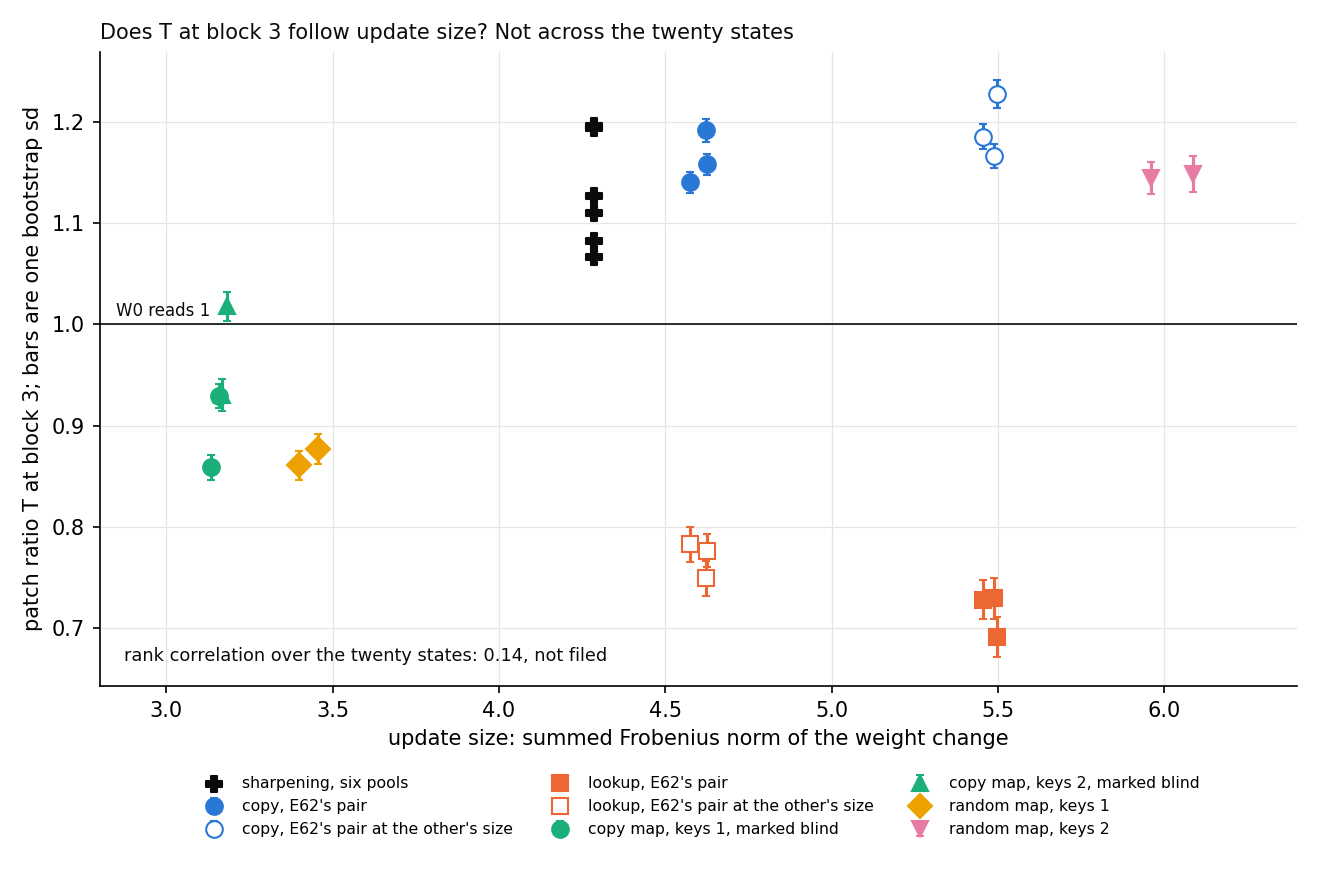

In [6]:
show("size.png")


**Reading it.** Not at block 3. At block 1 size matches by rank, but the shape of the pattern argues against it. Every correlation here is an analysis number, not a filed one. Over the twenty states at block 3 the rank correlation of $T$ with size is 0.14, where chance gives about 0.23 at that count. On the key maps at block 1 it is 0.95, over the 0.5 Fable used for the whole set. Those eight states are only four maps, and gain ranks them at 0.98, so size and gain cannot be told apart there.

Rescaling E62's states gives the direct test. $T$ moved along a straight line from 1 at zero size, within one noise unit at blocks 2 and 3. If that line held on the key maps, which is untested, a state below 1 would fall further as it grew, as the dotted lines show. The first random map would reach about 0.53 at the second's size, and the second reads 1.44. The copy maps would move by under 0.1 across the 9% step to the first random map, and that gap is 0.6. So on that one assumption, size ranks these maps but does not produce the pattern.


## What we learned

No label moved, and the table's rows stay "only by assumption". The patch itself works mechanically: W0's response grows block by block, and the transplant check reads exactly 0. It is not validated, because no state of known kind has read high on it.

On E62's pair the patch reads in the same order as E62's head test, which is suggestive and no more. On the key maps it runs against the assumption behind the copy-and-random row. That gives no support to reading the re-gating share as mechanism there. It does not contradict that reading either, since a low $T$ never earns "new".

**The granularity limit stands.** A new circuit built from old parts reads "elicited" to VPD. It can read as reuse here too if it multiplies on W0's state. "Reuse" on this patch could only mean old parts at the level of a block input.


## How compelling is the evidence

Weak, by design. One model, one donor, two or three seeds per map, six maps. Nothing was filed, so every comparison here was chosen after seeing the numbers. The pair bootstrap noise runs up to 0.15 at block 1 and 0.02 at block 3. The seed spread is about 0.05 on E62's pair and up to 0.19 at block 1. Twenty states are not twenty independent points.

**What $T$ cannot see.** An update upstream of the patch, attention at other positions, a new readout on old key features, and a mechanism W0 has but does not run on this input. Low $T$ never earns "new". Pairs picked on W0's own metric inflate $R(W_0)$, so $T$ can drift below 1 on any state. That applies to the lookup and the key maps, and not to the copying map's on-map pairs.


## Surprises

**Something unexpected happened that I cannot explain.** Copying maps were assumed to be reuse, so a reading of reuse should run higher on them. At block 1 they read far below the random maps and below every reference. On E62's pair the copying map runs above the lookup, the way E62's head test does. Each pattern could mean several things, listed in the report, and this run cannot separate them.

Also unexpected, in order of weight:

- The off-map ratio moves with $T$ at block 1, at a rank correlation of 0.88, so much of that fall is not specific to the trained target.
- The second random map, the largest update, reads above the write at every block on at least one seed.
- Rescaled states follow a straight line from 1 this closely.
- Fable expected E62's states to be marked blind at block 3. Measured steering stays under the bar of 0.5, at 0.48 at most.


## What next

Neither of Fable's outcomes fired, so nothing follows automatically. Three free checks, none planned yet.

1. **Rescale the key-map states and read block 1.** A straight line from 1 means the map's direction sets the reading. A rise with size on every map means size explains the pattern, and the patch has nothing to offer on this row.
2. **Read E62's copying map on ranked pairs, the lookup's rule.** If the order survives, the pair rule does not make it. If the copying map falls to the lookup, E62's agreement goes.
3. **A small amplify, at a gain W0's neurons can give.** If $T$ cannot read a known scaling, every high reading here means nothing. If it can, readings near 1 become informative.


## Scorecard

Filed controls only, from job 48971. No verdict is filed for any state.

| id | claim in words | read | verdict |
|---|---|---|---|
| C0 | the patch site is aligned | largest error 0, bar 1e-4 | pass |
| C2 | W0 responds at some block | every map has an l* | pass |
| C3 | few neurons carry W0's map | K = 4096; expected 64 to 256 | K found, outside what was expected |
| C4 | the write reads as a low control | error 0.45-1.41, bar 0.33 | missed on all five |
| C5 | amplify reads above the write | capped on all six | void; **the stop** |
| C6 | sharpening raises T, Q near 1 | T above on three of six; Q near 1 there | three read, three too weak |
| C7 | write's U on the null | above the null on all five | missed |
| C8 | gains reproduce | off by 0 on 14 | pass, job 49069 |


## Not run

- The 33 other saved states and the retraining of the 96-key rows.
- Any rule, label or method-table score.
- The neuron reading on any state.
- A rescaling of the key-map states.
- E62's copying map on ranked pairs.
- A rebuilt amplify.
- The text maps, patches at other positions, the key-swap patch and a second donor.

**Provenance.** Report `reports/analyses/2026-11-02_analysis_e66-interchange.md`. Results `experiments/interchange_67m/results/run.json` from MATS debug job 48971, and `amend2.json` from job 49069, each a few minutes at no cost. Figures and analysis numbers come from `plot.py` and `results/analysis_numbers.json`. Plan `reports/plans/2026-11-02_plan_e66-interchange-67m.md`, Amendments 1 and 2.
